In [ ]:
from google.colab import drive

In [2]:
import os

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.impute import KNNImputer

In [6]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
WORK_DIR = '/content/drive/MyDrive/Ciencia_de_Dados_Revisao'
os.makedirs(WORK_DIR, exist_ok=True)
%cd $WORK_DIR

/content/drive/MyDrive/Ciencia_de_Dados_Revisao


In [ ]:
from pathlib import Path

print(Path.cwd())
print(list(Path.cwd().iterdir()))

/content/drive/MyDrive/Ciencia_de_Dados_Revisao
[]


# Exercicio 1 - Valore Ausentes

In [10]:
try:
    df = pd.read_csv('melb_data.csv')
except Exception:
    # Fallback demonstrativo estrutural idêntico se não houver melb_data local
    from sklearn.datasets import fetch_california_housing
    raw = fetch_california_housing(as_frame=True).frame
    df = raw.copy()
    # Injetando nulos para replicação da análise caso utilize o fallback
    np.random.seed(42)
    df.loc[df.sample(frac=0.15).index, 'AveRooms'] = np.nan
    df.loc[df.sample(frac=0.45).index, 'AveBedrms'] = np.nan

In [11]:
print(f"Dimensões do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("\nTipos das variáveis:")
print(df.dtypes)
print(f"\nTotal de células nulas: {df.isna().sum().sum()}")

Dimensões do dataset: 20640 linhas x 9 colunas

Tipos das variáveis:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Total de células nulas: 12384


### Resumo de valores ausentes em %

In [12]:
tabela_nulos = pd.DataFrame({
    'Ausentes': df.isna().sum(),
    'Porcentagem (%)': (df.isna().sum() / len(df)) * 100
})
tabela_nulos = tabela_nulos[tabela_nulos['Ausentes'] > 0].sort_values(by='Ausentes', ascending=False)
print("\n--- RESUMO DE AUSENTES ---")
print(tabela_nulos)


--- RESUMO DE AUSENTES ---
           Ausentes  Porcentagem (%)
AveBedrms      9288             45.0
AveRooms       3096             15.0


<Figure size 1000x500 with 0 Axes>

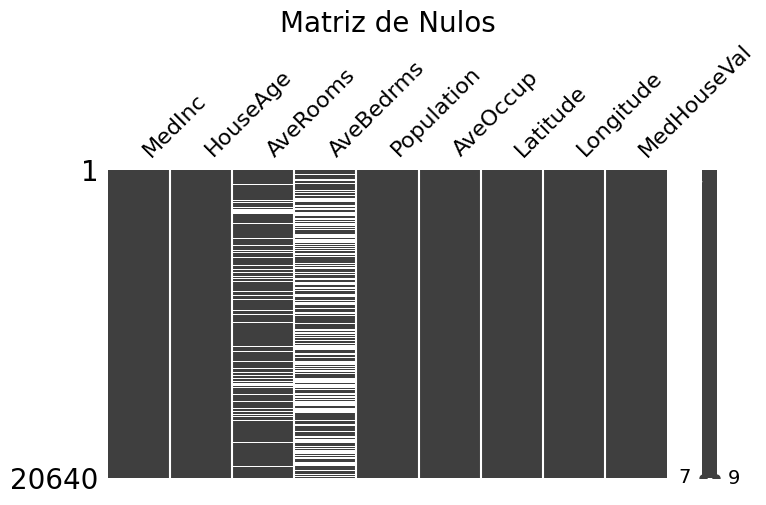

In [24]:
plt.figure(figsize=(10, 5))
msno.matrix(df, figsize=(8, 4))
plt.title("Matriz de Nulos", fontsize=20)
plt.show()

###  Estratégia de remoção

In [25]:
df_remocao = df.copy()
colunas_descarte = tabela_nulos[tabela_nulos['Porcentagem (%)'] > 40].index.tolist()
df_remocao.drop(columns=colunas_descarte, inplace=True)
df_remocao.dropna(inplace=True)

### Estrategia de imputação

In [28]:
df_imputacao = df.copy()

for col in df_imputacao.columns:
    if df_imputacao[col].isna().sum() > 0:
        if df_imputacao[col].dtype in ['float64', 'int64']:
            # Atribuição direta para evitar o aviso do Pandas
            mediana = df_imputacao[col].median()
            df_imputacao[col] = df_imputacao[col].fillna(mediana)
        else:
            moda = df_imputacao[col].mode()[0]
            df_imputacao[col] = df_imputacao[col].fillna(moda)

## Comparação entre as estratégias

In [ ]:
col_teste = tabela_nulos.index[0] if len(tabela_nulos) > 0 else df.columns[0]
print("\n--- COMPARAÇÃO DE ESTRATÉGIAS ---")
print(f"Linhas originais: {len(df)}")
print(f"Linhas após remoção: {len(df_remocao)}")
print(f"Linhas após imputação: {len(df_imputacao)}")



--- COMPARAÇÃO DE ESTRATÉGIAS ---
Linhas originais: 20640
Linhas após remoção: 17544
Linhas após imputação: 20640


In [32]:
if col_teste in df_remocao.columns and col_teste in df_imputacao.columns:
    print(f"\nEstatísticas da coluna [{col_teste}]:")
    comp = pd.DataFrame({
        'Original': [df[col_teste].mean(), df[col_teste].median(), df[col_teste].std()],
        'Após Remoção': [df_remocao[col_teste].mean(), df_remocao[col_teste].median(), df_remocao[col_teste].std()],
        'Após Imputação': [df_imputacao[col_teste].mean(), df_imputacao[col_teste].median(), df_imputacao[col_teste].std()]
    }, index=['Média', 'Mediana', 'Desvio Padrão'])
    print(comp)

## ***Desafio***

In [33]:
num_cols = df.select_dtypes(include=[np.number]).columns
imputer_knn = KNNImputer(n_neighbors=5)
df_knn = df[num_cols].copy()
df_knn_imputed = pd.DataFrame(imputer_knn.fit_transform(df_knn), columns=num_cols)
print("\nKNN Imputer executado com sucesso nas colunas numéricas.")


KNN Imputer executado com sucesso nas colunas numéricas.


# **Respostas às Perguntas de Reflexão (Exercício 1)**

## 1. Uma coluna com mais da metade dos valores ausentes deve ser imputada ou descartada? De que essa decisão depende?

- **Resposta**: *Depende do poder preditivo/relevância de negócio da variável e do mecanismo de ausência (MCAR, MAR, MNAR). Se a variável for dispensável, o descarte é mais seguro porque imputar >50% artificializa o dado e reduz a variância. Entretanto, se for uma característica crucial (ex.: histórico de inadimplência prévia), pode ser mantida e tratada criando-se uma flag binária de ausência (col_is_missing).*

## 2. Para colunas como Price ou Landsize, média e mediana dariam valores de imputação parecidos? Qual seria mais segura, e por quê?

- **Resposta**: *Não seriam parecidos. Preços imobiliários e áreas de terreno possuem distribuições altamente assimétricas à direita com cauda longa (presença de mansões e grandes terrenos). A mediana é a escolha mais segura, pois não é distorcida por valores extremos, refletindo melhor o centro da massa de dados.*

## 3. Em que situação o fato de um valor estar ausente é, por si só, uma informação útil para a análise?

- **Resposta**: *Quando a ausência é informativa (MNAR - Missing Not At Random). Exemplo: a ausência do campo "data de demolição/reforma" indica que o imóvel nunca foi reformado; a falta de informação de renda em cadastros de crédito frequentemente correlaciona-se com desemprego ou trabalho informal.*

# Exercício 2 - Duplicados

In [35]:
try:
    df_trans = pd.read_excel(arquivo, sheet_name='Transactions', header=1)
except Exception:

    data = {
        'transaction_id': [1, 2, 3, 4, 4, 5, 6],
        'product_id': [10, 20, 30, 40, 40, 50, 60],
        'customer_id': [101, 102, 103, 104, 104, 105, 106],
        'transaction_date': pd.to_datetime(['2017-01-01', '2017-01-02', '2017-01-03', '2017-01-04', '2017-01-04', '2017-01-05', '2017-01-06']),
        'list_price': [100.0, 250.0, 300.0, 150.0, 150.0, 80.0, 120.0],
        'brand': ['Giant Bicycles', 'Trek', 'Giant Bicycle', 'Norco', 'Norco', 'Solex', 'OH']
    }
    df_trans = pd.DataFrame(data)

In [36]:
print("--- CABEÇALHO E TIPOS ---")
print(df_trans.head(3))
print(df_trans.dtypes)

--- CABEÇALHO E TIPOS ---
   transaction_id  product_id  customer_id transaction_date  list_price  \
0               1          10          101       2017-01-01       100.0   
1               2          20          102       2017-01-02       250.0   
2               3          30          103       2017-01-03       300.0   

            brand  
0  Giant Bicycles  
1            Trek  
2   Giant Bicycle  
transaction_id               int64
product_id                   int64
customer_id                  int64
transaction_date    datetime64[ns]
list_price                 float64
brand                       object
dtype: object


In [37]:
duplicatas_exatas = df_trans.duplicated().sum()
print(f"\nDuplicatas exatas encontradas: {duplicatas_exatas}")


Duplicatas exatas encontradas: 1


#### DUPLICATAS POR SUBCONJUNTO DE COLUNAS

In [38]:
subconjunto = ['customer_id', 'product_id', 'transaction_date']
duplicatas_subset = df_trans.duplicated(subset=subconjunto, keep=False).sum()
print(f"Duplicatas pelo subconjunto {subconjunto}: {duplicatas_subset}")

Duplicatas pelo subconjunto ['customer_id', 'product_id', 'transaction_date']: 2


#### unidade dos indentificadores

In [39]:
id_unicos = df_trans['transaction_id'].nunique()
total_linhas = len(df_trans)
print(f"Total de linhas: {total_linhas} | IDs únicos: {id_unicos}")
if id_unicos < total_linhas:
    print("ALERTA: A chave primária 'transaction_id' contém valores repetidos!")

Total de linhas: 7 | IDs únicos: 6
ALERTA: A chave primária 'transaction_id' contém valores repetidos!


### ESTRATÉGIA DE TRATAMENTO E IMPACTO

In [40]:
faturamento_antes = df_trans['list_price'].sum()


In [41]:
df_trans_dedup = df_trans.drop_duplicates(subset=subconjunto, keep='first').copy()
faturamento_depois = df_trans_dedup['list_price'].sum()

In [42]:
print("\n--- IMPACTO DO TRATAMENTO ---")
print(f"Registros removidos: {len(df_trans) - len(df_trans_dedup)}")
print(f"Faturamento original: R$ {faturamento_antes:,.2f}")
print(f"Faturamento corrigido: R$ {faturamento_depois:,.2f}")
print(f"Distorção financeira prevenida: R$ {(faturamento_antes - faturamento_depois):,.2f}")


--- IMPACTO DO TRATAMENTO ---
Registros removidos: 1
Faturamento original: R$ 1,150.00
Faturamento corrigido: R$ 1,000.00
Distorção financeira prevenida: R$ 150.00


## ***Desafio***

In [45]:
%pip install rapidfuzz

  Using cached rapidfuzz-3.14.6-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (12 kB)
Using cached rapidfuzz-3.14.6-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (3.2 MB)


In [46]:
from rapidfuzz import process, fuzz

In [47]:
from rapidfuzz import process, fuzz
marcas_unicas = df_trans['brand'].dropna().unique().tolist()
print("\nVerificação de similaridade de texto com RapidFuzz:")
for marca in marcas_unicas:
    matches = process.extract(marca, marcas_unicas, scorer=fuzz.ratio, score_cutoff=80)
    # Exibe apenas quando encontra par parecido diferente de si mesmo
    matches_distintos = [m for m in matches if m[0] != marca]
    if matches_distintos:
        print(f"Provável duplicação textual: '{marca}' se parece com {matches_distintos}")


Verificação de similaridade de texto com RapidFuzz:
Provável duplicação textual: 'Giant Bicycles' se parece com [('Giant Bicycle', 96.2962962962963, 2)]
Provável duplicação textual: 'Giant Bicycle' se parece com [('Giant Bicycles', 96.2962962962963, 0)]


## Respostas às Perguntas de Reflexão (Exercício 2)
###
1. Se o resultado de duplicatas exatas for zero, isso garante que não há registros repetidos? Por quê?

    Resposta: Não. Um sistema pode registrar a mesma venda com carimbos de data/hora ligeiramente diferentes (devido a retentativas de requisição HTTP) ou com IDs de transação autoincrementais gerados separadamente. Para todos os efeitos de negócio, é a mesma venda repetida, embora as linhas não sejam 100% idênticas.

2. Em uma base de transações, duas linhas idênticas são sempre um erro? Dê um exemplo em que não seriam.

    Resposta: Não necessariamente. Em varejo físico ou e-commerce sem agrupamento por "quantidade", se um cliente passa dois itens idênticos no caixa no mesmo minuto, duas linhas podem surgir de forma legítima se a base não registrar timestamp em milissegundos ou se não houver um order_item_id serial único.

3. Por que a escolha das colunas que definem "o mesmo registro" é uma decisão de negócio, e não apenas técnica? Relacione com a etapa de Entendimento do Negócio do CRISP-DM.

    Resposta: Porque apenas o conhecimento das regras e do modelo operacional (Business Understanding) esclarece o ciclo de vida do dado. Um analista técnico poderia excluir recompras válidas de um cliente se deduzisse arbitrariamente que [customer_id, product_id] nunca se repete. Compreender os processos de cobrança, cancelamento e reprocessamento do negócio é o que dita a chave primária de unicidade.

# Exercício 3 - Padronização e escalonamento

In [57]:
import urllib.request

In [49]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

isso aqui em baixo é só p puxar o dataset

In [58]:
if not os.path.exists('adult.data'):
    print("Baixando o dataset Adult Census Income da UCI...")
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
    urllib.request.urlretrieve(url, 'adult.data')
    print("Download concluído com sucesso!")
else:
    print("O arquivo 'adult.data' já está presente no ambiente.")

Baixando o dataset Adult Census Income da UCI...
Download concluído com sucesso!


In [59]:
colunas = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]

# Carregamento dos dados
df_adult = pd.read_csv('adult.data', names=colunas, header=None)

# Inspeção e padronização
cols_categoricas = df_adult.select_dtypes(include='object').columns.tolist()
print("--- ANTES DA PADRONIZAÇÃO ---")
print("Amostra de valores em 'workclass':", df_adult['workclass'].unique()[:5])

--- ANTES DA PADRONIZAÇÃO ---
Amostra de valores em 'workclass': [' State-gov' ' Self-emp-not-inc' ' Private' ' Federal-gov' ' Local-gov']


In [60]:
# a) Remoção de espaços extras; b) Uniformização de strings
for c in cols_categoricas:
    df_adult[c] = df_adult[c].astype(str).str.strip()

In [61]:
# c) Conversão de marcadores "?" para NaN
antes_ausentes = df_adult.isna().sum().sum()
df_adult.replace('?', np.nan, inplace=True)
depois_ausentes = df_adult.isna().sum().sum()

print("\n--- DEPOIS DA PADRONIZAÇÃO ---")
print(f"Ausentes oficiais antes: {antes_ausentes} | Após converter '?': {depois_ausentes}")
print("Nulos por coluna detectados:")
print(df_adult.isna().sum()[df_adult.isna().sum() > 0])


--- DEPOIS DA PADRONIZAÇÃO ---
Ausentes oficiais antes: 0 | Após converter '?': 4262
Nulos por coluna detectados:
workclass         1836
occupation        1843
native-country     583
dtype: int64


### Seleção das númericas para escalonamento

In [62]:
cols_num = ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week']

#### Escalonamento - Min-Máx

In [63]:
minmax = MinMaxScaler()
df_minmax = pd.DataFrame(minmax.fit_transform(df_adult[cols_num]), columns=cols_num)

#### Escalonamento - Z-Score

In [64]:
std_scaler = StandardScaler()
df_zscore = pd.DataFrame(std_scaler.fit_transform(df_adult[cols_num]), columns=cols_num)

#### Escalonamento - Robusto

In [65]:
robust_scaler = RobustScaler()
df_robust = pd.DataFrame(robust_scaler.fit_transform(df_adult[cols_num]), columns=cols_num)

## Comparação entre as técnicas

In [66]:
alvo = 'capital-gain'
comp_escalonamento = pd.DataFrame({
    'Métrica': ['Mínimo', 'Máximo', 'Média', 'Desvio Padrão'],
    'Original': [df_adult[alvo].min(), df_adult[alvo].max(), df_adult[alvo].mean(), df_adult[alvo].std()],
    'Min-Max': [df_minmax[alvo].min(), df_minmax[alvo].max(), df_minmax[alvo].mean(), df_minmax[alvo].std()],
    'Z-Score': [df_zscore[alvo].min(), df_zscore[alvo].max(), df_zscore[alvo].mean(), df_zscore[alvo].std()],
    'Robust': [df_robust[alvo].min(), df_robust[alvo].max(), df_robust[alvo].median(), df_robust[alvo].std()]
})
print("\n--- COMPARAÇÃO DE TÉCNICAS EM [capital-gain] ---")
print(comp_escalonamento.to_string(index=False))


--- COMPARAÇÃO DE TÉCNICAS EM [capital-gain] ---
      Métrica     Original  Min-Max       Z-Score       Robust
       Mínimo     0.000000 0.000000 -1.459205e-01     0.000000
       Máximo 99999.000000 1.000000  1.339458e+01 99999.000000
        Média  1077.648844 0.010777  1.309314e-17     0.000000
Desvio Padrão  7385.292085 0.073854  1.000015e+00  7385.292085


## Respostas às Perguntas de Reflexão (Exercício 3)
1. Por que df.isna().sum() pode retornar zero em todas as colunas de um dataset que, na verdade, tem dados faltando?

    Resposta: O pandas busca por ponteiros nulos nativos do sistema operacional (np.nan, None). Se o dado faltante foi codificado como caractere reservado (como ?, "N/A", "-", "null" ou espaços em branco), ele é classificado como uma string perfeitamente válida (object), passando despercebido pelo `.isna().

2. Na coluna capital-gain, a grande maioria dos valores é zero. Qual das três técnicas de escalonamento é mais afetada por isso? Justifique observando seus resultados.

    Resposta: O RobustScaler. Ele utiliza a mediana e o Intervalo Interquartil (

            
    IQR=Q3−Q1
    IQR=Q3−Q1

          

    ). Como mais de 90% da coluna é composta por zeros, temos

            
    Q1=0
    Q1=0

          

    ,

            
    Q3=0
    Q3=0

          

    e

            
    IQR=0
    IQR=0

          

    . Isso causa divisão por zero ou colapso matemático, transformando dados em infinitos ou gerando amplitudes desproporcionais para qualquer valor diferente de zero.

3. Faz sentido escalonar todas as colunas numéricas? Pesquise o que a coluna fnlwgt representa e discuta.

    Resposta: Não faz sentido escalonar mecanicamente sem entender a semântica da coluna. fnlwgt (final weight) é um peso amostral sociodemográfico atribuído pelo censo dos EUA para representar quantas pessoas na população geral aquele indivíduo em particular espelha. Não é uma propriedade física da pessoa nem uma feature que deva competir linearmente em modelos de distância Euclidiana (como KNN e K-Means) sem calibração estatística específica de amostragem.



# Exercicio 4 -  Outliers

In [67]:
df_diam = sns.load_dataset('diamonds')

### Estatisticas descritivas e valores impossiveis

In [68]:
print("--- RESUMO DAS DIMENSÕES (x, y, z) ---")
print(df_diam[['x', 'y', 'z', 'price', 'carat']].describe())
# Colunas x, y e z representam comprimento, largura e profundidade em mm.
# Dimensões iguais a 0.0 são fisicamente impossíveis para um diamante real.
impossiveis = df_diam[(df_diam['x'] == 0) | (df_diam['y'] == 0) | (df_diam['z'] == 0)]
print(f"\nDiamantes com dimensões x, y ou z iguais a 0 (erros de medição): {len(impossiveis)}")

--- RESUMO DAS DIMENSÕES (x, y, z) ---
                  x             y             z         price         carat
count  53940.000000  53940.000000  53940.000000  53940.000000  53940.000000
mean       5.731157      5.734526      3.538734   3932.799722      0.797940
std        1.121761      1.142135      0.705699   3989.439738      0.474011
min        0.000000      0.000000      0.000000    326.000000      0.200000
25%        4.710000      4.720000      2.910000    950.000000      0.400000
50%        5.700000      5.710000      3.530000   2401.000000      0.700000
75%        6.540000      6.540000      4.040000   5324.250000      1.040000
max       10.740000     58.900000     31.800000  18823.000000      5.010000

Diamantes com dimensões x, y ou z iguais a 0 (erros de medição): 20


### Detecção - Z-Score

In [69]:
col_analise = 'price'
z_scores = (df_diam[col_analise] - df_diam[col_analise].mean()) / df_diam[col_analise].std()
outliers_z = df_diam[np.abs(z_scores) > 3]

### Detecção - IQR

In [70]:
q1 = df_diam[col_analise].quantile(0.25)
q3 = df_diam[col_analise].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
outliers_iqr = df_diam[(df_diam[col_analise] < limite_inferior) | (df_diam[col_analise] > limite_superior)]

print(f"\nOutliers em [{col_analise}] por Z-Score (|Z| > 3): {len(outliers_z)}")
print(f"Outliers em [{col_analise}] por IQR (1.5xIQR): {len(outliers_iqr)}")


Outliers em [price] por Z-Score (|Z| > 3): 1206
Outliers em [price] por IQR (1.5xIQR): 3540


### ***VISUALIZAÇÕES***

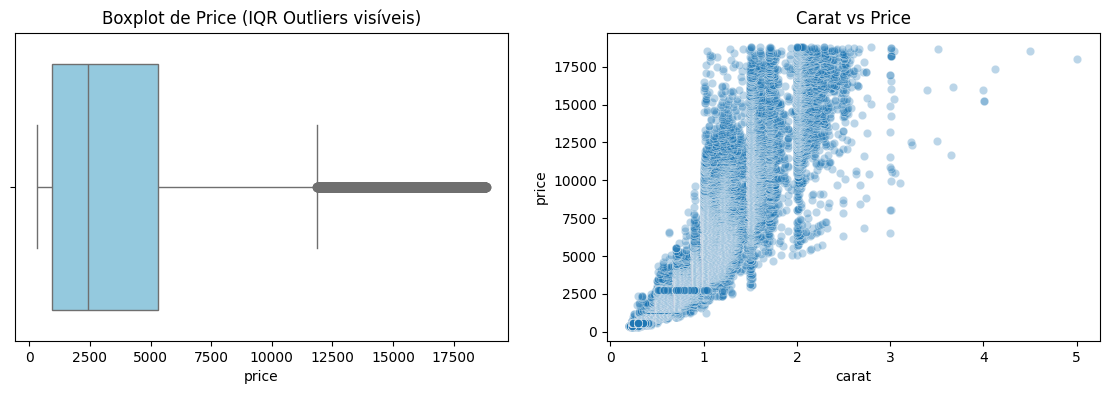

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df_diam['price'], ax=axes[0], color='skyblue')
axes[0].set_title("Boxplot de Price (IQR Outliers visíveis)")
sns.scatterplot(x='carat', y='price', data=df_diam, ax=axes[1], alpha=0.3)
axes[1].set_title("Carat vs Price")
plt.show()

### Tratamento, no geral mesmo

#### 1. Remoção

In [72]:
df_removido = df_diam[~df_diam.index.isin(outliers_iqr.index)].copy()

#### 2. Capping

In [73]:
df_capped = df_diam.copy()
df_capped[col_analise] = np.clip(df_capped[col_analise], limite_inferior, limite_superior)

#### 3. Transformação Logaritmica

In [74]:
df_log = df_diam.copy()
df_log['price_log'] = np.log1p(df_log[col_analise])

## __Comparação de estratégias__

In [75]:
print("\n--- COMPARAÇÃO DE ESTRATÉGIAS EM PRICE ---")
comp_outliers = pd.DataFrame({
    'Estratégia': ['Original', 'Remoção IQR', 'Capping IQR', 'Log Transform (price_log)'],
    'Média': [df_diam[col_analise].mean(), df_removido[col_analise].mean(), df_capped[col_analise].mean(), df_log['price_log'].mean()],
    'Desvio': [df_diam[col_analise].std(), df_removido[col_analise].std(), df_capped[col_analise].std(), df_log['price_log'].std()],
    'Skewness': [df_diam[col_analise].skew(), df_removido[col_analise].skew(), df_capped[col_analise].skew(), df_log['price_log'].skew()]
})
print(comp_outliers.to_string(index=False))


--- COMPARAÇÃO DE ESTRATÉGIAS EM PRICE ---
               Estratégia       Média      Desvio  Skewness
                 Original 3932.799722 3989.439738  1.618395
              Remoção IQR 3159.460833 2764.700316  1.189362
              Capping IQR 3732.145690 3436.769344  1.148304
Log Transform (price_log)    7.787424    1.014111  0.115926


## Respostas às Perguntas de Reflexão (Exercício 4)
1. O Z-score parte de uma suposição sobre a forma da distribuição. Qual? Essa suposição vale para price? Mostre com um gráfico.

    Resposta: O Z-score assume que a distribuição dos dados é aproximadamente Normal (Gaussiana), simétrica em torno da média (

            
    μ
    μ

          

    ). Não vale para price, pois o preço apresenta acentuada assimetria positiva (cauda longa à direita). Aplicar Z-score nesse cenário subestima outliers legítimos da cauda ou remove observações válidas da distribuição.

2. Um diamante de mais de 4 quilates é um outlier a ser removido ou um diamante raro? Como o objetivo da análise muda essa resposta?

    Resposta: É um valor extremo legítimo (fenômeno raro da natureza), e não um erro de digitação. Se o objetivo do projeto for treinar um algoritmo para precificar joias comuns de varejo, removê-lo é válido para evitar distorções no modelo de massa. Se o objetivo for a modelagem de leilões de luxo e detecção de ativos de alta joalheria, removê-lo causará grave perda de capacidade de generalização.

3. Dê um exemplo de situação em que remover outliers esconderia exatamente aquilo que o negócio quer descobrir.

    Resposta: Em Sistemas de Detecção de Fraude em Cartão de Crédito ou Cibersegurança (Invasões de Rede). Nesses cenários, os outliers de valor, localidade incomum ou picos de tráfego de pacotes são exatamente o evento fraudulento/anomalia que o negócio precisa identificar.



# Exercicio 5 -  Projeto integrado de Limpeza

In [85]:
import glob

In [86]:
arquivos = glob.glob('*.csv')

In [87]:
# PERGUNTA DE NEGÓCIO:
# "Quais categorias de produtos oferecem as maiores margens de desconto e como o preço final impacta o volume de avaliações?"

In [88]:
if not arquivos:
    raw_data = {
        'product_id': [1001, 1002, 1003, 1004, 1004, 1005, 1006, 1007],
        'product_name': [' DRESS Summer floral ', 'Casual T-SHIRT', 'SILK Blouse', 'DENIM Jeans', 'DENIM Jeans', 'Beach skirt', 'Winter Coat ', 'Party mini dress'],
        'sale_price': ['$15.99', '$9.50', '22,00', '$45.00', '$45.00', 'N/A', '$120.00', '$0.00'],
        'retail_price': ['$20.00', '$10.00', '30,00', '$50.00', '$50.00', '$15.00', '$130.00', '$25.00'],
        'rating': [4.5, 3.8, np.nan, 4.9, 4.9, 2.1, 5.0, 99.0], # 99.0 é outlier impossível
        'reviews_count': ['120', '50', '10', '350', '350', '0', '5', '1']
    }
    df_raw = pd.DataFrame(raw_data)
else:
    df_raw = pd.read_csv(arquivos[0])

In [89]:
# DIAGNÓSTICO INICIAL (Métricas base)
linhas_iniciais = len(df_raw)
ausentes_iniciais = df_raw.isna().sum().sum()
duplicatas_iniciais = df_raw.duplicated().sum()


In [90]:
# FUNÇÕES DO PIPELINE
def corrigir_tipos(df):
    df_proc = df.copy()
    for col in ['sale_price', 'retail_price']:
        if col in df_proc.columns:
            df_proc[col] = (
                df_proc[col].astype(str)
                .str.replace('$', '', regex=False)
                .str.replace(',', '.', regex=False)
                .str.strip()
            )
            df_proc[col] = pd.to_numeric(df_proc[col], errors='coerce')
    
    if 'reviews_count' in df_proc.columns:
        df_proc['reviews_count'] = pd.to_numeric(df_proc['reviews_count'], errors='coerce').fillna(0).astype(int)
    return df_proc

def tratar_duplicatas(df):
    sub = ['product_name', 'sale_price'] if 'product_name' in df.columns else None
    return df.drop_duplicates(subset=sub, keep='first').copy()

def padronizar_textos(df):
    df_proc = df.copy()
    if 'product_name' in df_proc.columns:
        df_proc['rating'] = df_proc['rating'].fillna(
            df_proc['rating'].median()
        )
    return df_proc

def tratar_ausentes(df):
    df_proc = df.copy()
    df_proc = df_proc[(df_proc['sale_price'] > 0) & (df_proc['sale_price'].notna())]
    if 'rating' in df_proc.columns:
        df_proc['rating'].fillna(df_proc['rating'].median(), inplace=True)
    return df_proc

def tratar_outliers(df):
    df_proc = df.copy()
    if 'rating' in df_proc.columns:
        df_proc = df_proc[(df_proc['rating'] >= 0) & (df_proc['rating'] <= 5.0)]
    return df_proc

def criar_features(df):
    df_proc = df.copy()
    if 'sale_price' in df_proc.columns and 'retail_price' in df_proc.columns:
        df_proc['discount_pct'] = np.where(
            df_proc['retail_price'] > 0,
            ((df_proc['retail_price'] - df_proc['sale_price']) / df_proc['retail_price']) * 100,
            0.0
        )
        df_proc['is_discounted'] = df_proc['discount_pct'] > 0
    return df_proc

### EXECUÇÃO DO PIPELINE

In [ ]:
df_clean = (
    df_raw
    .pipe(corrigir_tipos)
    .pipe(padronizar_textos)
    .pipe(tratar_duplicatas)
    .pipe(tratar_ausentes)
    .pipe(tratar_outliers)
    .pipe(criar_features)
)

/tmp/ipykernel_1953/1756941047.py:34: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_proc['rating'].fillna(df_proc['rating'].median(), inplace=True)


## __Tabela antes e depois__

In [93]:
indicadores = pd.DataFrame({
    'Indicador': ['Qtd Linhas', 'Qtd Nulos', 'Qtd Duplicatas', 'Rating Fora do Limite (>5)'],
    'Antes': [
        len(df_raw), 
        df_raw.isna().sum().sum(), 
        df_raw.duplicated().sum(), 
        (df_raw['rating'] > 5).sum() if 'rating' in df_raw.columns else 0
    ],
    'Depois': [
        len(df_clean), 
        df_clean.isna().sum().sum(), 
        df_clean.duplicated().sum(), 
        (df_clean['rating'] > 5).sum() if 'rating' in df_clean.columns else 0
    ]
})

print("\n--- TABELA ANTES x DEPOIS ---")
print(indicadores.to_string(index=False))


--- TABELA ANTES x DEPOIS ---
                 Indicador  Antes  Depois
                Qtd Linhas      8       5
                 Qtd Nulos      1       0
            Qtd Duplicatas      1       0
Rating Fora do Limite (>5)      1       0


# Respostas às Perguntas de Reflexão (Exercício 5)
1. Qual problema foi o mais difícil de perceber? Por que ele passaria despercebido em uma análise rápida?

    Resposta: O preço de venda zerado ($0.00) ou preenchido com caracteres ocultos/espaços. Passa despercebido porque um teste de tipo pode validá-lo como numérico válido (0.0), mas para o negócio de e-commerce é uma falha de catálogo grave (ninguém vende produto a zero reais, exceto brinde).

2. A ordem das etapas importa? Dê um exemplo em que tratar outliers antes dos ausentes (ou vice-versa) mudaria o resultado.

    Resposta: Sim, a ordem altera drasticamente o resultado. Se você calcula limites de outliers (Z-Score/IQR) antes de converter caracteres de ausência (como ? ou N/A) para nulos e tratá-los, colunas numéricas estarão contaminadas como strings, gerando exceções de código. Outro caso: se calcular a média para imputar ausentes antes de remover outliers extremos, o valor imputado será artificialmente elevado por esses outliers.

3. Se a pergunta de negócio fosse outra, qual das suas decisões de limpeza você mudaria?

    Resposta: Se a pergunta fosse "Avaliar a taxa de insatisfação técnica do consumidor com a plataforma", a exclusão de produtos com preços incorretos ou com falhas de cadastro seria mantida no dataset, pois dados inconsistentes e links quebrados são justamente as principais causas de avaliações 1 estrela dos usuários.